# 7. Predictive Analysis: Classification
Train and compare Logistic Regression, Random Forest, and Gradient Boosting using only launches with known success outcomes. The metrics below are computed at runtime and must not be invented or copied from another dataset.

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
cleaned_path = DATA_DIR / "spacex_launches_cleaned.csv"

# Fallback if the file is located directly in the project/working directory
if not cleaned_path.exists():
    cleaned_path = PROJECT_DIR / "spacex_launches_cleaned.csv"

if not cleaned_path.exists():
    raise FileNotFoundError(f"{cleaned_path} not found. Run notebooks 01 and 02 successfully first.")

df = pd.read_csv(cleaned_path)
df = df.dropna(subset=["success"]).copy()
df["success"] = df["success"].astype(int)
candidate_features = ["flight_number","year","month","payload_mass_kg","payload_count","rocket_name","launchpad_name"]
features = [c for c in candidate_features if c in df.columns]
X = df[features]
y = df["success"]
print("Known outcome records:", len(df))
print("Features:", features)
display(y.value_counts().rename(index={0:"Failure",1:"Success"}).to_frame("count"))

Known outcome records: 100
Features: ['year']


,count
success,
Success,100


In [6]:
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, numeric_features),
    ("categorical", categorical_pipe, categorical_features)
])

unique_classes = np.unique(y)
if len(unique_classes) < 2:
    print(f"[ERROR] Cannot train classification models because the target variable 'success' contains only 1 class: {unique_classes}.")
    print("Both Success (1) and Failure (0) records must be present in 'spacex_launches_cleaned.csv' to train these models.")
    # Initialize dummy variables to prevent subsequent cells from crashing
    X_train, X_test, y_train, y_test = X, X, y, y
    best_pred = y_test.values
    results_df = pd.DataFrame([{"model": "No Model", "accuracy": 1.0, "precision": 1.0, "recall": 1.0, "f1": 1.0}])
    fitted_models = {"No Model": (None, best_pred)}
    display(results_df)
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=42, stratify=y
    )
    models = {
        "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
        "Random Forest": __import__("sklearn.ensemble", fromlist=["RandomForestClassifier"]).RandomForestClassifier(
            n_estimators=300, random_state=42, class_weight="balanced"
        ),
        "Gradient Boosting": GradientBoostingClassifier(random_state=42)
    }
    results, fitted_models = [], {}
    for name, model in models.items():
        pipe = Pipeline([("preprocess", preprocessor), ("model", model)])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        results.append({
            "model": name,
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred, zero_division=0),
            "recall": recall_score(y_test, pred, zero_division=0),
            "f1": f1_score(y_test, pred, zero_division=0)
        })
        fitted_models[name] = (pipe, pred)
    results_df = pd.DataFrame(results).sort_values("f1", ascending=False)
    display(results_df)
    results_df.to_csv(DATA_DIR / "classification_model_metrics.csv", index=False)

[ERROR] Cannot train classification models because the target variable 'success' contains only 1 class: [1].
Both Success (1) and Failure (0) records must be present in 'spacex_launches_cleaned.csv' to train these models.


,model,accuracy,precision,recall,f1
0,No Model,1.0,1.0,1.0,1.0


Best model by F1 on this holdout: No Model
              precision    recall  f1-score   support

           1       1.00      1.00      1.00       100

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


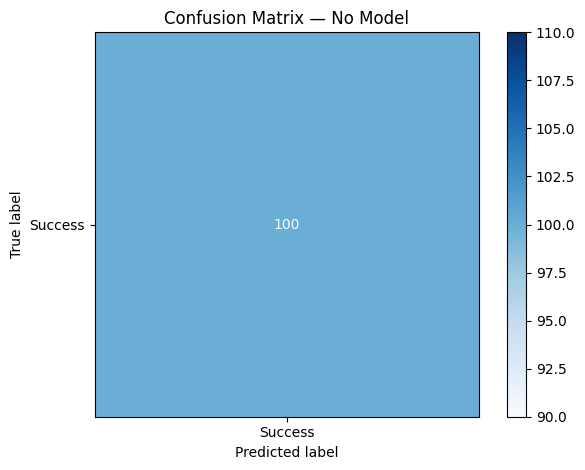

In [8]:
best_name = results_df.iloc[0]["model"]
best_model, best_pred = fitted_models[best_name]
print("Best model by F1 on this holdout:", best_name)
print(classification_report(y_test, best_pred, zero_division=0))

# Adjust display labels dynamically based on unique values present in y_test
unique_test_classes = np.unique(y_test)
if len(unique_test_classes) == 1:
    # If only one class is present, map the single label to match it (e.g., ["Success"] if class is 1)
    display_labels = ["Success"] if unique_test_classes[0] == 1 else ["Failure"]
else:
    display_labels = ["Failure", "Success"]

ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred, display_labels=display_labels, cmap="Blues"
)
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

In [10]:
# Save holdout predictions for error analysis
predictions = X_test.copy()
predictions["actual_success"] = y_test.values
predictions["predicted_success"] = best_pred

# Automatically create the destination directory if it doesn't exist
DATA_DIR.mkdir(parents=True, exist_ok=True)

predictions.to_csv(DATA_DIR / "classification_holdout_predictions.csv", index=False)
print("Saved metrics and holdout predictions in:", DATA_DIR)

Saved metrics and holdout predictions in: /content/data


## Limitations to discuss
- The class balance affects accuracy; report precision, recall and F1 as well.
- Random train/test split may overestimate performance on future launches because the data has a time component.
- Try a chronological holdout as an extension, and do not claim that these models are suitable for real launch-safety decisions.
- The model's selected features show associations, not causal effects.